# AgriSmartAI - Notebook 06: Centralized Model Benchmark Dashboard
### Systematic Performance Comparison Across All ML Tasks

**Objective**: Programmatically load and display experiment comparison tables generated from notebooks 02, 03, and 04.

## 1. Load Experiment Result Tables

In [1]:
import os
import sys

def get_project_root():
    cwd = os.getcwd()
    if os.path.basename(cwd) == 'notebooks':
        return os.path.abspath(os.path.join(cwd, '..'))
    return cwd

PROJECT_ROOT = get_project_root()
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

def get_path(rel_path):
    clean_rel = rel_path.replace('../', '').replace('./', '')
    p1 = os.path.join(PROJECT_ROOT, clean_rel)
    if os.path.exists(p1):
        return p1
    p2 = os.path.join(os.getcwd(), rel_path)
    if os.path.exists(p2):
        return p2
    return p1

import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

tables_dir = '../outputs/evaluation/tables'
df_crop = pd.read_csv(os.path.join(tables_dir, 'crop_recommendation_results.csv'))
df_yield = pd.read_csv(os.path.join(tables_dir, 'crop_yield_results.csv'))
df_fert = pd.read_csv(os.path.join(tables_dir, 'fertilizer_recommendation_results.csv'))




## 2. Crop Recommendation Model Comparison Table

In [2]:
display(df_crop)

,Rank,Model,Accuracy,Precision,Recall,Macro_F1,Weighted_F1,CV_F1,Status
0,1,Random Forest,0.920455,0.925788,0.920455,0.910772,0.910772,93.27% ± 1.78%,Selected Production Deployment
1,2,CatBoost,0.915909,0.930282,0.915909,0.910310,0.910310,92.59% ± 0.39%,Benchmark Runner-Up
2,3,XGBoost,0.911364,0.914359,0.911364,0.908518,0.908518,93.79% ± 1.53%,Gradient Boosted Tree
3,4,Support Vector Machine,0.872727,0.897206,0.872727,0.865174,0.865174,89.01% ± 1.92%,High Margin Kernel
4,5,K-Nearest Neighbours,0.829545,0.878777,0.829545,0.811860,0.811860,83.60% ± 2.10%,Instance Based
5,6,Logistic Regression,0.777273,0.784194,0.777273,0.749623,0.749623,72.43% ± 1.42%,Linear Baseline
6,7,Decision Tree,0.227273,0.161765,0.227273,0.171717,0.171717,17.08% ± 0.18%,Unconstrained Tree


## 3. Crop Yield Prediction Regressor Comparison Table

In [3]:
display(df_yield)

,Rank,Model,R2,RMSE,MAE,MAPE,CV_R2,Status
0,1,LightGBM,0.898932,4.306449,3.797536,140.369206,0.9033 ± 0.0044,Selected Production Deployment
1,2,CatBoost,0.875113,4.787084,4.230991,157.720099,0.8817 ± 0.0051,Benchmark Runner-Up
2,3,Gradient Boosting,0.822472,5.707507,5.200529,207.940383,0.8300 ± 0.0072,Ensemble Regressor
3,4,XGBoost,0.820579,5.737851,5.227656,208.276379,0.8279 ± 0.0071,Tree Regressor
4,5,Random Forest,0.737306,6.942854,5.970107,237.213215,0.7388 ± 0.0134,Bagging Regressor
5,6,Decision Tree,0.737081,6.945832,5.972957,236.997599,0.7380 ± 0.0134,Single Tree Regressor
6,7,Linear Regression,0.616128,8.392791,6.349709,233.223983,0.6148 ± 0.0043,Constrained Linear Baseline


## 4. Fertilizer Recommendation Classifier Comparison Table

In [4]:
display(df_fert)

,Model,Accuracy,Precision,Recall,Weighted_F1,Macro_F1,CV_F1
0,Random Forest,92.95%,94.49%,92.95%,93.03%,93.48%,93.29% ± 0.82%
1,CatBoost,91.75%,93.62%,91.75%,91.84%,91.27%,90.54% ± 1.21%
2,Logistic Regression,86.25%,86.10%,86.25%,86.13%,84.97%,82.92% ± 0.27%
3,Support Vector Machine,87.95%,87.87%,87.95%,87.77%,84.27%,83.66% ± 1.10%
4,Decision Tree,90.40%,83.09%,90.40%,86.47%,67.93%,67.75% ± 0.18%
5,XGBoost,83.00%,79.47%,83.00%,76.84%,55.78%,54.70% ± 1.61%


## 5. Multi-Panel Performance Comparison Chart

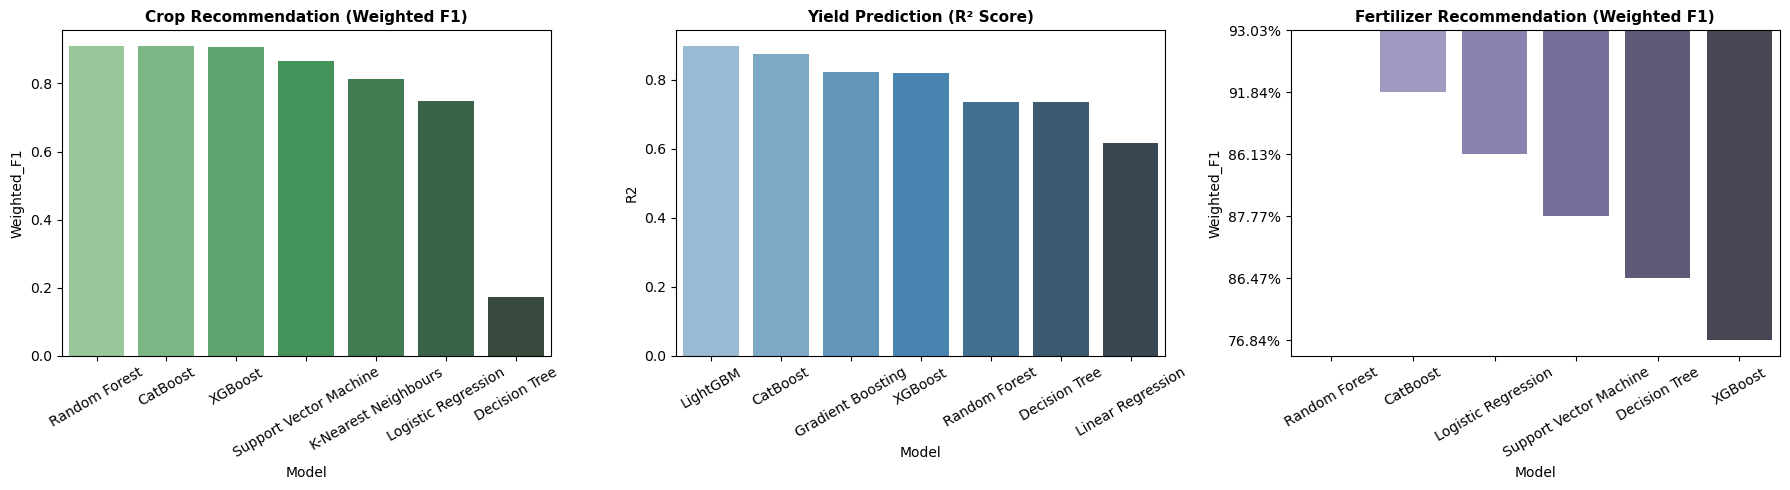

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.barplot(data=df_crop, x='Model', y='Weighted_F1', hue='Model', palette='Greens_d', legend=False, ax=axes[0])
axes[0].set_title('Crop Recommendation (Weighted F1)', fontsize=11, fontweight='bold')
axes[0].tick_params(axis='x', rotation=30)

sns.barplot(data=df_yield, x='Model', y='R2', hue='Model', palette='Blues_d', legend=False, ax=axes[1])
axes[1].set_title('Yield Prediction (R² Score)', fontsize=11, fontweight='bold')
axes[1].tick_params(axis='x', rotation=30)

sns.barplot(data=df_fert, x='Model', y='Weighted_F1', hue='Model', palette='Purples_d', legend=False, ax=axes[2])
axes[2].set_title('Fertilizer Recommendation (Weighted F1)', fontsize=11, fontweight='bold')
axes[2].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()